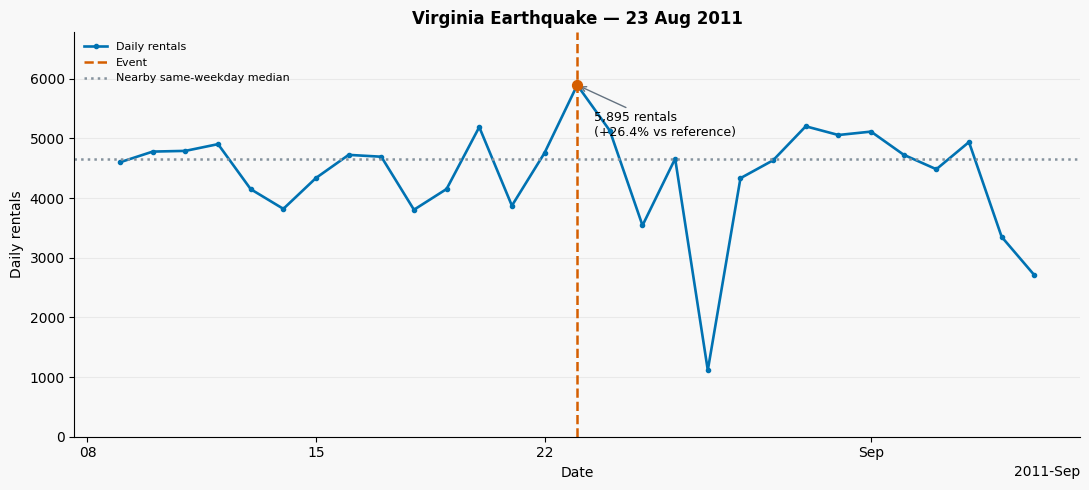

Virginia Earthquake: 5,895 rentals; reference 4,663.5; descriptive difference +26.4%


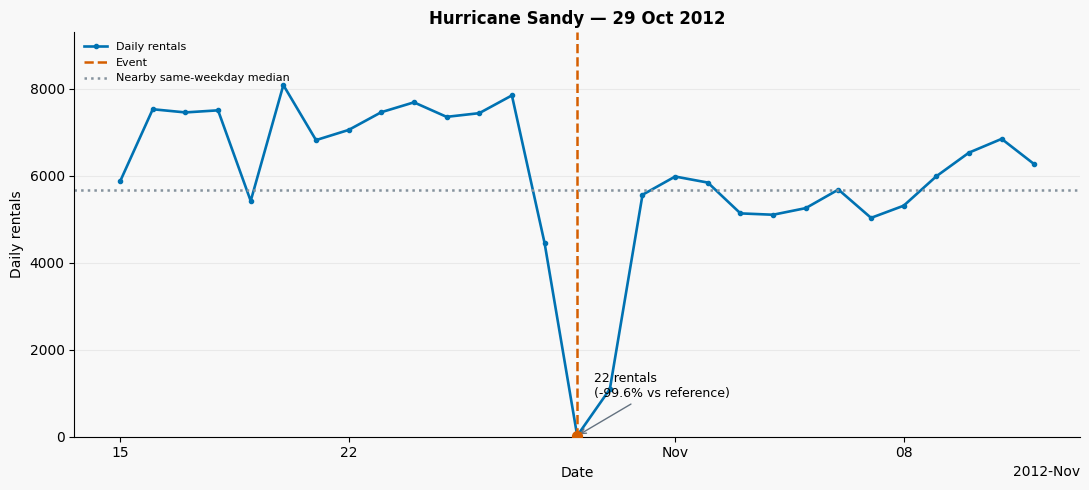

Hurricane Sandy: 22 rentals; reference 5,687.0; descriptive difference -99.6%


In [1]:
# Eventi straordinari

# Importiamo le librerie per analizzare e visualizzare i noleggi nel tempo.
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# Impostiamo colori e sfondo coerenti con gli altri notebook.
MUTED = '#647280'
REGISTERED = '#0072B2'
ACCENT = '#D55E00'
NEUTRAL = '#86939E'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Apriamo il CSV giornaliero e convertiamo la colonna delle date.
day = pd.read_csv('../data/processed/bike_day_clean.csv')
day['dteday'] = pd.to_datetime(day['dteday'])

# Indichiamo i due eventi da confrontare con i noleggi vicini nel tempo.
events = {
    '2011-08-23': 'Virginia Earthquake',
    '2012-10-29': 'Hurricane Sandy'
}

# Creiamo la cartella in cui salvare un'immagine per ciascun evento.
OUT = Path('../output/figures')
OUT.mkdir(parents=True, exist_ok=True)

# Analizziamo un evento per volta e produciamo due grafici separati.
for date, name in events.items():
    fig, ax = plt.subplots(figsize=(11, 5))
    t = pd.Timestamp(date)

    # Selezioniamo le osservazioni dei 14 giorni prima e dopo l'evento.
    window = day.loc[day['dteday'].between(
        t - pd.Timedelta(days=14), t + pd.Timedelta(days=14)
    )]
    event_rentals = int(day.loc[day['dteday'] == t, 'cnt'].iloc[0])

    # Prendiamo come riferimento lo stesso giorno della settimana nelle 4 settimane vicine.
    nearby = (
        day['dteday'].between(t - pd.Timedelta(days=28), t + pd.Timedelta(days=28))
        & day['dteday'].dt.day_of_week.eq(t.day_of_week)
        & day['dteday'].ne(t)
    )

    # Confrontiamo i noleggi osservati con la mediana dei giorni di riferimento.
    reference = day.loc[nearby, 'cnt'].median()
    delta = (event_rentals / reference - 1) * 100

    # Disegniamo la serie giornaliera, la data dell'evento e la mediana.
    ax.plot(window['dteday'], window['cnt'], color=REGISTERED,
            marker='o', markersize=3, linewidth=1.9, label='Daily rentals')
    ax.axvline(t, color=ACCENT, linestyle='--', linewidth=1.8, label='Event')
    ax.axhline(reference, color=NEUTRAL, linestyle=':', linewidth=1.8,
               label='Nearby same-weekday median')
    ax.scatter(t, event_rentals, color=ACCENT, s=50, zorder=5)

    # Scriviamo il valore dell'evento direttamente accanto al punto.
    ax.annotate(
        f'{event_rentals:,} rentals\n({delta:+.1f}% vs reference)',
        xy=(t, event_rentals),
        xytext=(12, -37) if event_rentals > reference else (12, 28),
        textcoords='offset points', fontsize=9,
        arrowprops={'arrowstyle': '->', 'color': MUTED}
    )

    # Aggiungiamo etichette, legenda e date leggibili.
    ax.set_title(f'{name} — {t:%d %b %Y}', fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Daily rentals')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8, loc='upper left')
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.tick_params(axis='x', rotation=0)
    ax.set_ylim(bottom=0, top=window['cnt'].max() * 1.15)

    # Salviamo separatamente i due grafici.
    # Precisiamo quando la copertura delle osservazioni è incompleta.
    note = ('Only one recorded hour on Sandy day; service coverage is incomplete.'
            if 'Sandy' in name else
            'Descriptive comparison; changes cannot be attributed to the earthquake.')

    # Salviamo ciascun evento con il prefisso del notebook 08.
    filename = ('RQ8A_earthquake.png' if 'Earthquake' in name
                else 'RQ8B_hurricane_sandy.png')
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=200, bbox_inches='tight')
    plt.show()

    # Stampiamo una sola volta i risultati numerici.
    print(f'{name}: {event_rentals:,} rentals; reference {reference:,.1f}; '
          f'descriptive difference {delta:+.1f}%')
